# 05 – Model mv1 na *S. cerevisiae*: deterministyczność i porównanie z baseline

In [10]:
import sys
sys.path.insert(0, "..")

import logging
import random
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
import torch
from torch.utils.data import DataLoader

from data.dataset import JunctionDataset, collate_junction_batch
from data.loader import load_training_csv, kfold_splits
from models.mv1 import Mv1JunctionModel
from training.trainer import Trainer

for _name in ["training.trainer", "data.dataset", "data.loader", "training.metrics"]:
    logging.getLogger(_name).setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("../../data/training/cerevisiae_training.csv")
BASES = ["A", "C", "G", "T"]

print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

Torch: 2.12.0+cu130 | CUDA: False


In [11]:
labeled, stats = load_training_csv(DATA_PATH, only_labeled=True)
stats.print()

Dataset statistics (Polars Engine):
  Total rows:          10840
  Usable (labeled):    3939  (36.3%)
  Ambiguous:           5496
  Not in reference:    0
  Label distribution:  {'T': 1205, 'A': 1306, 'C': 687, 'G': 741}
  Avg context length:  44.7 bp
  Avg branch length:   67.2 bp
  Avg out-degree:      2.09
  Coverage (min/mean/max): 22 / 223 / 7606


In [12]:
rows = labeled.select(["ground_truth"] + [f"branch_{b}_cov" for b in BASES]).to_dicts()
correct, total_valid = 0, 0
for row in rows:
    gt = row["ground_truth"]
    cov = {b: (row[f"branch_{b}_cov"] or 0.0) for b in BASES}
    if any(v > 0 for v in cov.values()):
        total_valid += 1
        if max(cov, key=cov.get) == gt:
            correct += 1

BASELINE_ACC = correct / total_valid if total_valid else 0.0
print(f"Baseline (max-coverage, n={total_valid}): {BASELINE_ACC*100:.1f}%")

Baseline (max-coverage, n=3939): 58.4%


In [13]:
def train_fold(
    df_train: pl.DataFrame,
    df_val: pl.DataFrame,
    *,
    seed: int = 42,
    context_len: int = 100,
    branch_len: int = 100,
    augment: bool = True,
    use_cov: bool = True,
    epochs: int = 100,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    early_stop: int = 15,
    batch_size: int = 32,
    embed_dim: int = 64,
    hidden_dim: int = 64,
    dropout: float = 0.3,
) -> dict:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    train_ds = JunctionDataset(
        df_train, context_len=context_len, branch_len=branch_len,
        augment=augment, use_cov_feat=use_cov,
    )
    val_ds = JunctionDataset(
        df_val, context_len=context_len, branch_len=branch_len,
        augment=False, use_cov_feat=use_cov,
    )
    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        collate_fn=collate_junction_batch, num_workers=0,
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        collate_fn=collate_junction_batch, num_workers=0,
    )

    cov_dim = 6 if use_cov else 0
    model = Mv1JunctionModel(
        context_embed_dim=embed_dim, branch_embed_dim=embed_dim,
        cov_feat_dim=cov_dim, hidden_dim=hidden_dim, dropout=dropout,
    )

    tmpdir = tempfile.mkdtemp(prefix="cv_fold_")
    trainer = Trainer(
        model, checkpoint_dir=Path(tmpdir),
        learning_rate=lr, weight_decay=weight_decay,
        epochs=epochs, early_stop=early_stop,
    )
    history = trainer.fit(train_loader, val_loader)

    return {
        "junction_accuracy": max(e.junction_accuracy for e in history.val),
        "f1": max(e.f1 for e in history.val),
        "epochs_run": len(history.val),
    }

In [ ]:
# Stale uzywane przez wiele komorek ponizej.
# Mozna odpalic te komorke i przeskoczyc bezposrednio do wybranej komorki
# (np. context sweep) bez koniecznosci uruchamiania wolnych komorek treningowych.
N_SPLITS = 5
CV_SEED  = 42

color_model    = "#5b9bd5"
color_baseline = "#e05c5c"

In [ ]:
print(f"5-fold CV | seed={CV_SEED} | labeled junctions: {labeled.height}")
print("-" * 60)

splits_cv = kfold_splits(labeled, n_splits=N_SPLITS, seed=CV_SEED)
cv_results = []

for fold_idx, (df_train, df_val) in enumerate(splits_cv):
    print(f"  Fold {fold_idx+1}/{N_SPLITS}  "
          f"(train={df_train.height} val={df_val.height}) ", end="", flush=True)
    result = train_fold(df_train, df_val, seed=CV_SEED)
    cv_results.append(result)
    print(
        f"junc_acc={result['junction_accuracy']*100:.1f}%  "
        f"F1={result['f1']:.3f}  "
        f"({result['epochs_run']} epok)"
    )

accs_cv = [r["junction_accuracy"] for r in cv_results]
f1s_cv  = [r["f1"] for r in cv_results]

print("-" * 60)
print(f"  Junction accuracy: {np.mean(accs_cv)*100:.1f}% ± {np.std(accs_cv)*100:.1f}%")
print(f"  F1:                {np.mean(f1s_cv):.3f} ± {np.std(f1s_cv):.3f}")

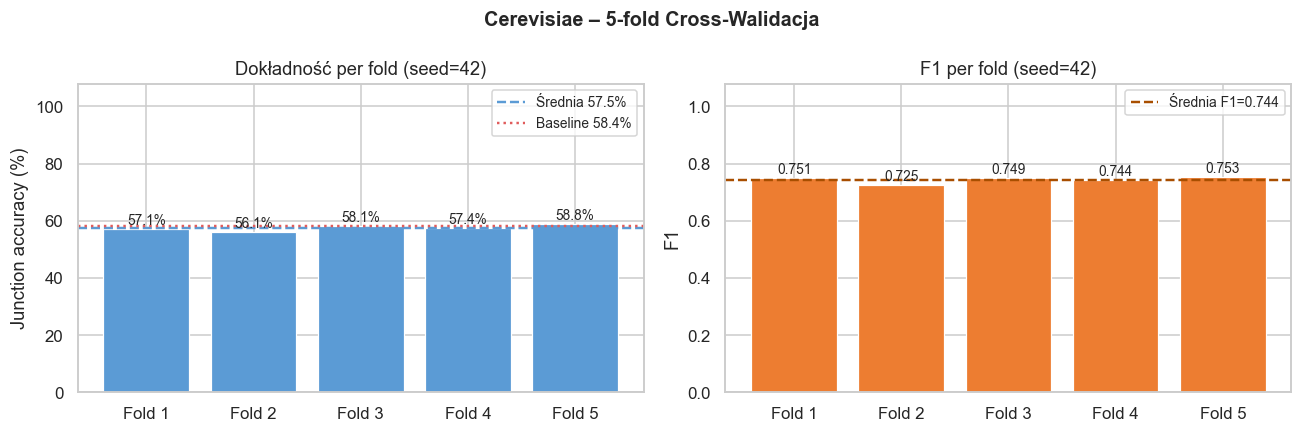

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fold_labels = [f"Fold {i+1}" for i in range(N_SPLITS)]
color_model    = "#5b9bd5"
color_baseline = "#e05c5c"

# --- Junction accuracy per fold ---
ax = axes[0]
bars = ax.bar(fold_labels, [a * 100 for a in accs_cv],
              color=color_model, edgecolor="white", linewidth=0.8)
ax.axhline(np.mean(accs_cv) * 100, color=color_model, linestyle="--", linewidth=1.6,
           label=f"Średnia {np.mean(accs_cv)*100:.1f}%")
ax.axhline(BASELINE_ACC * 100, color=color_baseline, linestyle=":", linewidth=1.6,
           label=f"Baseline {BASELINE_ACC*100:.1f}%")
for bar, acc in zip(bars, accs_cv):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{acc*100:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 108)
ax.set_ylabel("Junction accuracy (%)")
ax.set_title(f"Dokładność per fold (seed={CV_SEED})")
ax.legend(fontsize=9)

# --- F1 per fold ---
ax = axes[1]
bars2 = ax.bar(fold_labels, f1s_cv,
               color="#ed7d31", edgecolor="white", linewidth=0.8)
ax.axhline(np.mean(f1s_cv), color="#a84e00", linestyle="--", linewidth=1.6,
           label=f"Średnia F1={np.mean(f1s_cv):.3f}")
for bar, f1 in zip(bars2, f1s_cv):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
            f"{f1:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1")
ax.set_title(f"F1 per fold (seed={CV_SEED})")
ax.legend(fontsize=9)

plt.suptitle("Cerevisiae – 5-fold Cross-Walidacja", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Diagnostyka: sekwencja vs pokrycie

Jeden fold — z i bez cech pokrycia — żeby sprawdzić czy CNN uczy się z sekwencji DNA.
Baseline liczony na **tym samym val foldzie** co model (uczciwe porównanie).

In [ ]:
df_train_diag, df_val_diag = kfold_splits(labeled, n_splits=5, seed=42)[0]

# Baseline na val foldzie (uczciwe – te same przykłady co model)
rows_val = df_val_diag.select(["ground_truth"] + [f"branch_{b}_cov" for b in BASES]).to_dicts()
correct_val, total_val = 0, 0
for row in rows_val:
    gt = row["ground_truth"]
    cov = {b: (row[f"branch_{b}_cov"] or 0.0) for b in BASES}
    if any(v > 0 for v in cov.values()):
        total_val += 1
        if max(cov, key=cov.get) == gt:
            correct_val += 1
BASELINE_VAL = correct_val / total_val if total_val else 0.0
print(f"Baseline (val fold, n={total_val}): {BASELINE_VAL*100:.1f}%")

print("\nTrening z pokryciem (use_cov=True)...")
r_cov = train_fold(df_train_diag, df_val_diag, seed=42, use_cov=True)

print("Trening bez pokrycia (use_cov=False)...")
r_seq = train_fold(df_train_diag, df_val_diag, seed=42, use_cov=False)

print()
print(f"{'':32s}  {'Junc acc':>9}  {'vs baseline':>12}  {'epoki':>6}")
print("-" * 66)
print(f"{'Baseline (max-cov, val fold)':32s}  {BASELINE_VAL*100:>8.1f}%  {'—':>12}  {'—':>6}")
print(f"{'Model z pokryciem':32s}  {r_cov['junction_accuracy']*100:>8.1f}%  "
      f"{(r_cov['junction_accuracy']-BASELINE_VAL)*100:>+11.1f}pp  "
      f"{r_cov['epochs_run']:>6}")
print(f"{'Model BEZ pokrycia':32s}  {r_seq['junction_accuracy']*100:>8.1f}%  "
      f"{(r_seq['junction_accuracy']-BASELINE_VAL)*100:>+11.1f}pp  "
      f"{r_seq['epochs_run']:>6}")
print("-" * 66)

Baseline (val fold, n=788): 58.9%

Trening z pokryciem (use_cov=True)...

Best epoch: 3
  Val junction accuracy: 54.44%
  Val pair accuracy:     56.62%
  Val F1:                0.7230
  Val loss:              0.7428
Trening bez pokrycia (use_cov=False)...

Best epoch: 1
  Val junction accuracy: 55.96%
  Val pair accuracy:     58.69%
  Val F1:                0.7397
  Val loss:              0.6778

                                   Junc acc   vs baseline   epoki
------------------------------------------------------------------
Baseline (max-cov, val fold)          58.9%             —       —
Model z pokryciem                     54.4%         -4.4pp      18
Model BEZ pokrycia                    56.0%         -2.9pp      16
------------------------------------------------------------------


## Analiza błędów: dokładność vs rzeczywista długość kontekstu

Pytanie: czy model myli się losowo, czy błędy skupiają się na krótkich sekwencjach?
Trenujemy model (ctx=150, no_cov, fold 1), robimy inference na val foldzie i grupujemy junctiony po rzeczywistej długości context_seq.

Trening modelu do analizy bledow (ctx=150, no_cov, fold 1)...

Best epoch: 8
  Val junction accuracy: 58.38%
  Val pair accuracy:     60.87%
  Val F1:                0.7568
  Val loss:              0.6586
Val junctions: 788

       Bin      n      Model    Baseline    delta
------------------------------------------------
     20-30    276      62.7%       63.0%    -0.4pp
     30-40     54      55.6%       72.2%   -16.7pp
     40-50     52      57.7%       63.5%    -5.8pp
     50-60     29      58.6%       55.2%    +3.4pp
     60-80     28      53.6%       53.6%    +0.0pp
       >80    349      55.9%       53.6%    +2.3pp


NameError: name 'color_model' is not defined

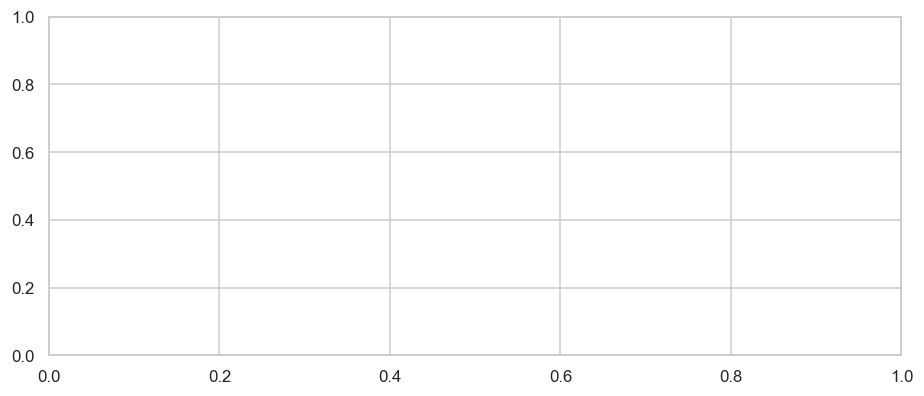

In [15]:
def predict_on_val(
    df_train: pl.DataFrame,
    df_val: pl.DataFrame,
    *,
    seed: int = 42,
    context_len: int = 150,
    use_cov: bool = False,
    embed_dim: int = 64,
    hidden_dim: int = 64,
    dropout: float = 0.3,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    epochs: int = 100,
    early_stop: int = 15,
    batch_size: int = 32,
) -> pl.DataFrame:
    """Trenuje model i zwraca per-junction wyniki na val foldzie."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    train_ds = JunctionDataset(df_train, context_len=context_len, branch_len=100,
                                augment=True, use_cov_feat=use_cov)
    val_ds   = JunctionDataset(df_val,   context_len=context_len, branch_len=100,
                                augment=False, use_cov_feat=use_cov)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               collate_fn=collate_junction_batch, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                               collate_fn=collate_junction_batch, num_workers=0)

    cov_dim = 6 if use_cov else 0
    model = Mv1JunctionModel(context_embed_dim=embed_dim, branch_embed_dim=embed_dim,
                              cov_feat_dim=cov_dim, hidden_dim=hidden_dim, dropout=dropout)

    tmpdir = tempfile.mkdtemp(prefix="err_analysis_")
    trainer = Trainer(model, checkpoint_dir=Path(tmpdir),
                      learning_rate=lr, weight_decay=weight_decay,
                      epochs=epochs, early_stop=early_stop)
    trainer.fit(train_loader, val_loader)

    ckpt = torch.load(Path(tmpdir) / "mv1_siamese_cnn_best.pt",
                      map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    # Polars gives Python ints; explicit int() guards against edge cases
    ctx_len_lookup = {
        int(jid): int(ctx)
        for jid, ctx in zip(df_val["junction_id"].to_list(), df_val["context_len"].to_list())
    }

    baseline_lookup: dict[int, int] = {}
    for row in df_val.select(
        ["junction_id", "ground_truth"] + [f"branch_{b}_cov" for b in BASES]
    ).iter_rows(named=True):
        gt  = row["ground_truth"]
        cov = {b: (row[f"branch_{b}_cov"] or 0.0) for b in BASES}
        if any(v > 0 for v in cov.values()):
            baseline_lookup[int(row["junction_id"])] = int(max(cov, key=cov.get) == gt)

    # batch["junction_id"] iterates as 0-dim tensors; .item() converts to Python int
    # so dict keys match those in ctx_len_lookup / baseline_lookup
    junc_pairs: dict[int, list[bool]] = {}
    with torch.no_grad():
        for batch in val_loader:
            sim_a, sim_b = model(
                batch["context"], batch["branch_a"],
                batch["branch_b"], batch["cov_feat"],
            )
            preds = torch.stack([sim_a, sim_b], dim=1).argmax(dim=1)
            for jid_t, pred, label in zip(
                batch["junction_id"], preds.tolist(), batch["label"].tolist()
            ):
                jid = jid_t.item()  # 0-dim tensor -> Python int
                junc_pairs.setdefault(jid, []).append(pred == label)

    rows = [
        {
            "junction_id":      jid,
            "ctx_len_actual":   ctx_len_lookup.get(jid, 0),
            "model_correct":    int(all(pairs)),
            "baseline_correct": baseline_lookup.get(jid, 0),
        }
        for jid, pairs in junc_pairs.items()
    ]
    return pl.DataFrame(rows)


# --- Uruchomienie ---
print("Trening modelu do analizy bledow (ctx=150, no_cov, fold 1)...")
pred_df = predict_on_val(df_train_diag, df_val_diag, seed=42, context_len=150, use_cov=False)
print(f"Val junctions: {pred_df.height}")

# --- Binning po rzeczywistej dlugosci context_seq ---
BINS   = [0, 20, 30, 40, 50, 60, 80, 400]
BIN_LB = ["<20", "20-30", "30-40", "40-50", "50-60", "60-80", ">80"]

def ctx_bin(ctx_len: int) -> str:
    for lo, hi, label in zip(BINS[:-1], BINS[1:], BIN_LB):
        if lo <= ctx_len < hi:
            return label
    return BIN_LB[-1]

bin_stats: dict[str, dict] = {lb: {"m_ok": 0, "b_ok": 0, "n": 0} for lb in BIN_LB}
for row in pred_df.iter_rows(named=True):
    lb = ctx_bin(row["ctx_len_actual"])
    bin_stats[lb]["m_ok"] += row["model_correct"]
    bin_stats[lb]["b_ok"] += row["baseline_correct"]
    bin_stats[lb]["n"]    += 1

# --- Tabela ---
print(f"\n{'Bin':>10}  {'n':>5}  {'Model':>9}  {'Baseline':>10}  {'delta':>7}")
print("-" * 48)
active = [(lb, bin_stats[lb]) for lb in BIN_LB if bin_stats[lb]["n"] > 0]
for lb, d in active:
    m = d["m_ok"] / d["n"] * 100
    b = d["b_ok"] / d["n"] * 100
    print(f"{lb:>10}  {d['n']:>5}  {m:>8.1f}%  {b:>9.1f}%  {m-b:>+6.1f}pp")

# --- Wykres ---
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(active))
w = 0.35
m_accs = [d["m_ok"] / d["n"] * 100 for _, d in active]
b_accs = [d["b_ok"] / d["n"] * 100 for _, d in active]
ns     = [d["n"] for _, d in active]
lbs    = [lb for lb, _ in active]

bars_m = ax.bar(x - w/2, m_accs, w, label="Model (ctx=150, no_cov)", color=color_model)
bars_b = ax.bar(x + w/2, b_accs, w, label="Baseline (max-coverage)", color=color_baseline)
for i, n in enumerate(ns):
    ax.text(x[i], 2, f"n={n}", ha="center", fontsize=8, color="white", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(lbs)
ax.set_xlabel("Rzeczywista dlugosc context_seq (bp)")
ax.set_ylabel("Junction accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Dokladnosc vs rzeczywista dlugosc kontekstu -- fold 1, ctx=150, no_cov")
ax.legend()
plt.tight_layout()
plt.show()

## Sweep context_len (bez pokrycia, embed_dim=64)

Sprawdzamy czy dluzszy kontekst sekwencji zblizy model do baseline 58.9%.
Srednia dlugosc kontekstu w danych to 44.7 bp, wiec wartosci 100-250 to juz padding.

In [ ]:
CTX_LENS = [100, 150, 200, 250]
EMBED_DIM = 64

print(f"Context sweep | {N_SPLITS}-fold CV | embed_dim={EMBED_DIM} | use_cov=False | seed={CV_SEED}")
print(f"Baseline (global, n={labeled.height}): {BASELINE_ACC*100:.1f}%")
print()
print(f"{'ctx_len':>8}  {'mean acc':>9}  {'std':>6}  {'vs baseline':>12}  {'epoki':>7}")
print("-" * 52)

ctx_cv_results = {}
for ctx in CTX_LENS:
    fold_accs, fold_eps = [], []
    for df_tr, df_vl in kfold_splits(labeled, n_splits=N_SPLITS, seed=CV_SEED):
        r = train_fold(df_tr, df_vl, seed=CV_SEED, use_cov=False,
                       context_len=ctx, embed_dim=EMBED_DIM)
        fold_accs.append(r["junction_accuracy"])
        fold_eps.append(r["epochs_run"])
    ctx_cv_results[ctx] = fold_accs
    m, s = np.mean(fold_accs), np.std(fold_accs)
    print(f"{ctx:>8}  {m*100:>8.1f}%  {s*100:>5.1f}%  "
          f"{(m - BASELINE_ACC)*100:>+11.1f}pp  {np.mean(fold_eps):>6.1f}")

print("-" * 52)
best_ctx = max(ctx_cv_results, key=lambda k: np.mean(ctx_cv_results[k]))
best_mean = np.mean(ctx_cv_results[best_ctx])
best_std  = np.std(ctx_cv_results[best_ctx])
print(f"Najlepszy: context_len={best_ctx} -> "
      f"{best_mean*100:.1f}% ± {best_std*100:.1f}%  "
      f"(vs baseline {(best_mean - BASELINE_ACC)*100:+.1f}pp)")

In [ ]:
from IPython.display import display

rows_summary = [
    {
        "Eksperyment": "Baseline (max-cov, val fold)",
        "Junc acc (%)": f"{BASELINE_VAL*100:.1f}",
        "vs baseline (pp)": "—",
        "Uwagi": "heurystyka, ten sam fold co model",
    },
    {
        "Eksperyment": f"5-fold CV, ctx=100 (seed={CV_SEED})",
        "Junc acc (%)": f"{np.mean(accs_cv)*100:.1f} ± {np.std(accs_cv)*100:.1f}",
        "vs baseline (pp)": f"{(np.mean(accs_cv)-BASELINE_ACC)*100:+.1f}  (vs global)",
        "Uwagi": "use_cov=True (domyslny), embed=64",
    },
    {
        "Eksperyment": "Diagnostyka z pokryciem (fold 1)",
        "Junc acc (%)": f"{r_cov['junction_accuracy']*100:.1f}",
        "vs baseline (pp)": f"{(r_cov['junction_accuracy']-BASELINE_VAL)*100:+.1f}",
        "Uwagi": f"ep. {r_cov['epochs_run']}, use_cov=True",
    },
    {
        "Eksperyment": "Diagnostyka BEZ pokrycia (fold 1)",
        "Junc acc (%)": f"{r_seq['junction_accuracy']*100:.1f}",
        "vs baseline (pp)": f"{(r_seq['junction_accuracy']-BASELINE_VAL)*100:+.1f}",
        "Uwagi": f"ep. {r_seq['epochs_run']}, tylko sekwencja",
    },
]

# Dodaj wyniki context sweep (jesli byly uruchomione)
try:
    for ctx in CTX_LENS:
        m = np.mean(ctx_cv_results[ctx])
        s = np.std(ctx_cv_results[ctx])
        rows_summary.append({
            "Eksperyment": f"5-fold CV, ctx={ctx}, no_cov",
            "Junc acc (%)": f"{m*100:.1f} ± {s*100:.1f}",
            "vs baseline (pp)": f"{(m-BASELINE_ACC)*100:+.1f}  (vs global)",
            "Uwagi": f"embed={EMBED_DIM}, use_cov=False",
        })
except NameError:
    pass

display(pl.DataFrame(rows_summary))

print()
print("=" * 60)
print("WNIOSKI")
print("=" * 60)
delta_cv = (np.mean(accs_cv) - BASELINE_ACC) * 100
if delta_cv > 0:
    print(f"  5-fold CV: model bije baseline o {delta_cv:.1f} pp "
          f"({np.mean(accs_cv)*100:.1f}% vs {BASELINE_ACC*100:.1f}%).")
else:
    print(f"  5-fold CV: model nie bije baseline ({np.mean(accs_cv)*100:.1f}% vs "
          f"{BASELINE_ACC*100:.1f}%) — coverage jest zbyt silnym skrotem przy ctx=100.")
delta_fair = (r_cov['junction_accuracy'] - BASELINE_VAL) * 100
print(f"  Diagnostyka (fair): model z pokryciem {delta_fair:+.1f} pp vs baseline na val foldzie.")
delta_seq = (r_seq['junction_accuracy'] - r_cov['junction_accuracy']) * 100
if abs(delta_seq) < 3:
    print(f"  Sekwencja vs pokrycie: roznica {abs(delta_seq):.1f} pp — CNN uczy sie czegos z sekwencji.")
else:
    print(f"  Sekwencja vs pokrycie: {abs(delta_seq):.1f} pp — pokrycie jest dominujacym sygnałem.")
try:
    best_ctx_mean = np.mean(ctx_cv_results[best_ctx])
    print(f"  Context sweep: najlepszy ctx={best_ctx} -> "
          f"{best_ctx_mean*100:.1f}% (vs baseline {(best_ctx_mean-BASELINE_ACC)*100:+.1f} pp).")
except NameError:
    pass
print("=" * 60)